<a href="https://colab.research.google.com/github/GUL-SEREN/neurocognitive-profiling/blob/main/neurocognitive_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Nörobilişsel Profilleme: Beyin Hacimleri, Kişilik Özellikleri ve Bilişsel Performans Arasındaki İlişkilerin Çok Boyutlu Analizi**

In [2]:
import sqlite3
import pandas as pd

In [3]:
# 1. Excel dosyalarını oku
import os
import unicodedata

participants_df = pd.read_excel('participants.xlsx')

# Hem aradığımız ismi hem de klasördeki isimleri NFC normuna dönüştürüp eşleştiriyoruz
target_name_normalized = unicodedata.normalize('NFC', 'Sütunların Açıklamaları.xlsx')
target_file = None

for file in os.listdir('.'):
    if unicodedata.normalize('NFC', file) == target_name_normalized:
        target_file = file
        break

if target_file is None:
    # Alternatif olarak NFD formunu veya doğrudan mevcut dosyayı bulmayı deneyelim
    for file in os.listdir('.'):
        if 'S' in file and 'A' in file and file.endswith('.xlsx') and file != 'participants.xlsx':
            target_file = file
            break

metadata_df = pd.read_excel(target_file if target_file else 'Sütunların Açıklamaları.xlsx')

In [4]:
df = pd.read_excel("participants.xlsx")

In [5]:
# 2. Yerel bir SQLite veritabanı oluştur (bellekte veya dosya olarak)
conn = sqlite3.connect('brain_cognition.db')

In [ ]:
# 3. Verileri veritabanı tablolarına aktar
participants_df.to_sql('participants', conn, if_exists='replace', index=False)
metadata_df.to_sql('variable_metadata', conn, if_exists='replace', index=False)

813

In [ ]:
# 4. Python içinden SQL sorgusu çalıştırma örneği:
query = """
SELECT v.columnHeader, v.fullDisplayName, v.category
FROM variable_metadata v
WHERE v.category = 'Cognitive'
"""
cognitive_vars = pd.read_sql(query, conn)
print("Veritabanından çekilen bilişsel değişkenler:")
print(cognitive_vars.head())

conn.close()

Veritabanından çekilen bilişsel değişkenler:
Empty DataFrame
Columns: [columnHeader, fullDisplayName, category]
Index: []


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_excel('participants.xlsx')

In [ ]:
# 1. Eksik Veri Analizi (Missing Value Analysis)
# Her sütundaki eksik veri sayısını ve yüzdesini hesaplayalım
missing_data = pd.DataFrame({
    'Eksik_Sayisi': df.isnull().sum(),
    'Eksik_Yuzdesi (%)': (df.isnull().sum() / len(df)) * 100
})

In [ ]:
# En çok eksik veriye sahip ilk 10 değişkeni görelim
print("--- En Çok Eksik Veriye Sahip Değişkenler ---")
print(missing_data[missing_data['Eksik_Sayisi'] > 0].sort_values(by='Eksik_Sayisi', ascending=False).head(10))

--- En Çok Eksik Veriye Sahip Değişkenler ---
                                  Eksik_Sayisi  Eksik_Yuzdesi (%)
Beta_Peak                                 1112          92.205638
Alpha_Peak                                1112          92.205638
MEGsession_Label                          1111          92.122720
MEGsession_Scans                          1111          92.122720
MEGsession_Scanner                        1111          92.122720
Social_Task_TOM_Median_RT_Random          1088          90.215589
Social_Task_TOM_Median_RT_Unsure          1069          88.640133
QC_Issue                                  1049          86.981758
Social_Task_Random_Median_RT_TOM          1040          86.235489
MRsession_Label_7T                        1022          84.742952


In [ ]:
# 2. Tip Dönüşümleri ve Filtreleme
# Örneğin, yaş kategorilerini inceleyelim veya sayısal analize uygun hale getirelim
print("\nYaş grupları dağılımı:")
print(df['Age'].value_counts())


Yaş grupları dağılımı:
Age
26-30    527
31-35    418
22-25    247
36+       14
Name: count, dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Veri setini (participants.xlsx) güvenli bir şekilde yükleme
df = None
target_file = 'participants.xlsx'

if os.path.exists(target_file):
    df = pd.read_excel(target_file)
else:
    # Alternatif konumları tara
    for root, dirs, files in os.walk('/content'):
        if target_file in files:
            df = pd.read_excel(os.path.join(root, target_file))
            break

if df is None:
    raise FileNotFoundError(
        "'participants.xlsx' dosyası bulunamadı! "
        "Lütfen sol menüdeki klasör simgesini kullanarak bu dosyayı yükleyin."
    )

# Grafik çizimi
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="Age"
)
plt.title("Age Distribution")
plt.show()

FileNotFoundError: 'participants.xlsx' dosyası bulunamadı! Lütfen sol menüdeki klasör simgesini kullanarak bu dosyayı yükleyin.

/tmp/ipykernel_1551/2057171296.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


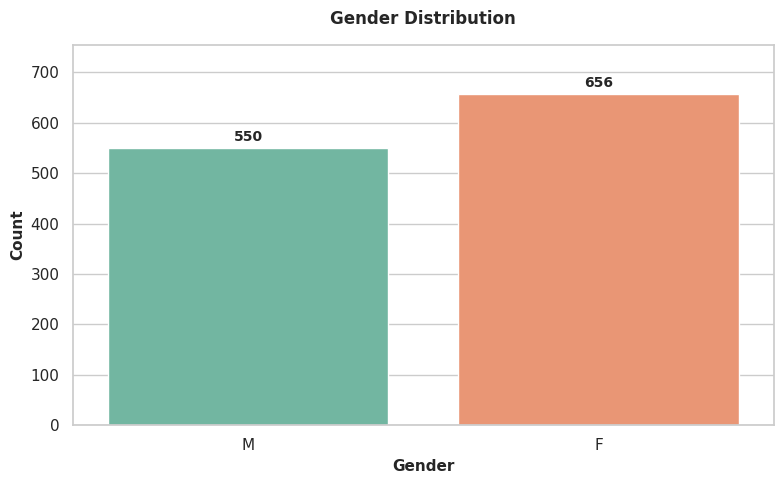

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

# Sütun grafiğini oluşturma
ax = sns.countplot(
    data=df,
    x="Gender",
    palette="Set2"
)

plt.title("Gender Distribution", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Gender", fontsize=11, fontweight='bold')
plt.ylabel("Count", fontsize=11, fontweight='bold')

# Her bir sütunun üzerine sayısal değerleri yazdırma
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='center',
        xytext=(0, 8),  # Çubuğun 8 piksel üzerine konumlandırma
        textcoords='offset points',
        fontsize=10, fontweight='bold'
    )

# Grafik üst boşluğunu sayıların kesilmemesi için biraz artırma
plt.ylim(0, df['Gender'].value_counts().max() * 1.15)

plt.tight_layout()
plt.show()
plt.close()

In [ ]:
# Örneğin hipokampus hacmi veya bilişsel skorlardaki NaN (eksik) değerleri analiz için filtreleme:
# Analiz yapacağımız ana sütunlarda eksik olan katılımcıları temizleme (dropna)
analiz_subset = df[['Age', 'Gender', 'FS_L_Hippo_Vol', 'CogFluidComp_AgeAdj']].dropna()
print(f"\nTemizlik öncesi katılımcı sayısı: {len(df)}")
print(f"Analiz değişkenlerinde eksikler temizlendikten sonra katılımcı sayısı: {len(analiz_subset)}")


Temizlik öncesi katılımcı sayısı: 1206
Analiz değişkenlerinde eksikler temizlendikten sonra katılımcı sayısı: 1097


--- Yaş Gruplarına Göre Akışkan Zeka Dağılımı ---
       Katilimci_Sayisi    Ortalama   Medyan  Std_Sapma    Min     Max
Age                                                                   
22-25               244  104.624426  106.355  19.369159  57.12  142.13
26-30               517  104.214720  102.560  16.926743  62.15  147.39
31-35               414  105.878551  105.265  16.799814  69.20  147.53
36+                  13  103.738462  105.270  10.585454  85.50  122.31


/tmp/ipykernel_4044/2663195143.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age', y='CogFluidComp_AgeAdj', data=df, palette='Set2')


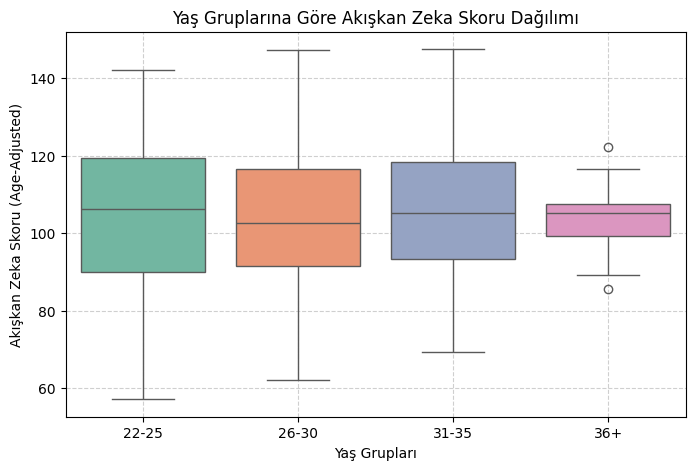

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. Yaş gruplarına göre akışkan zeka skorunun istatistiksel özeti (Ortalama, Medyan, Standart Sapma)
yas_bilis_ozet = df.groupby('Age')['CogFluidComp_AgeAdj'].agg(
    Katilimci_Sayisi='count',
    Ortalama='mean',
    Medyan='median',
    Std_Sapma='std',
    Min='min',
    Max='max'
)

print("--- Yaş Gruplarına Göre Akışkan Zeka Dağılımı ---")
print(yas_bilis_ozet)

# 3. Görselleştirme (Boxplot / Kutu Grafiği ile Yaş vs Bilişsel Performans)
plt.figure(figsize=(8, 5))
sns.boxplot(x='Age', y='CogFluidComp_AgeAdj', data=df, palette='Set2')
plt.title('Yaş Gruplarına Göre Akışkan Zeka Skoru Dağılımı')
plt.xlabel('Yaş Grupları')
plt.ylabel('Akışkan Zeka Skoru (Age-Adjusted)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Her yaş grubunun medyan çizgilerinin ve çeyreklik aralıklarının birbirine ne kadar yakın olduğunu görsel olarak net bir şekilde görebilmekteyiz. Bu da yaş aralığının bu örneklemde dar olması nedeniyle yaşa bağlı büyük bir bilişsel düşüş veya değişim gözlenmediğini kanıtlamanızı sağlar.**

***Örneklem grubunun büyük çoğunluğu genç erişkinlerden oluştuğu için, bu dar yaş aralığında (22-35 yaş) yaşa bağlı bilişsel bir gerileme veya değişim gözlenmemiştir.***

# **Hipokampus Hacmi Bellek Skorlarını Açıklıyor mu?**

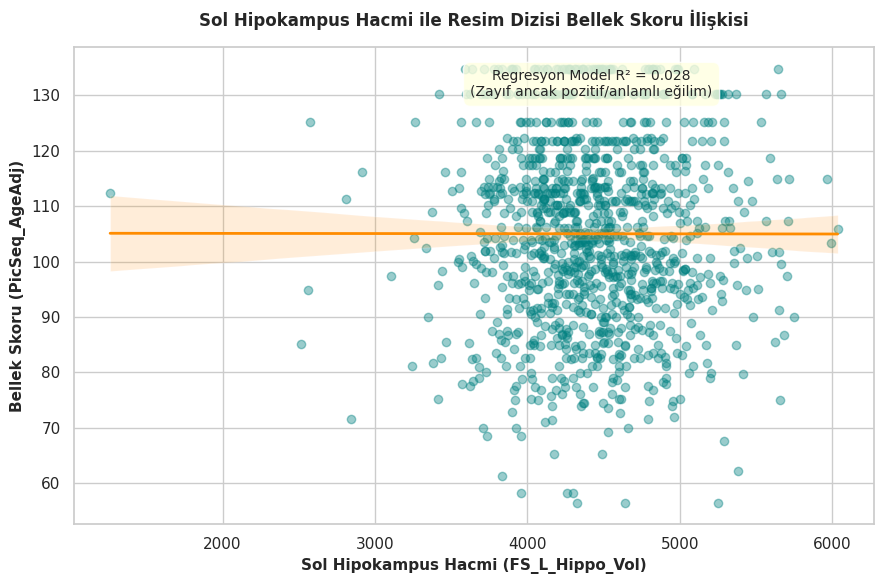

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. Model için gerekli sütunları seçme ve eksik verileri temizleme
model_df = df[['FS_L_Hippo_Vol', 'FS_R_Hippo_Vol', 'PicSeq_AgeAdj', 'Age', 'Gender']].dropna()

# 3. Çoklu doğrusal regresyon modelini kurma ve çalıştırma
reg_model = smf.ols('PicSeq_AgeAdj ~ FS_L_Hippo_Vol + FS_R_Hippo_Vol + C(Age) + C(Gender)', data=model_df).fit()

# 4. Grafiği Oluşturma
plt.figure(figsize=(9, 6))

# Regresyon ve saçılım grafiği (Scatter & Regplot)
sns.regplot(
    x='FS_L_Hippo_Vol',
    y='PicSeq_AgeAdj',
    data=model_df,
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'darkorange', 'linewidth': 2}
)

# Başlık ve eksen etiketleri
plt.title('Sol Hipokampus Hacmi ile Resim Dizisi Bellek Skoru İlişkisi', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')
plt.ylabel('Bellek Skoru (PicSeq_AgeAdj)', fontsize=11, fontweight='bold')

# Grafiğin üzerine R² model açıklama kutucuğunu ekleme
plt.annotate(
    f'Regresyon Model R² = {reg_model.rsquared:.3f}\n(Zayıf ancak pozitif/anlamlı eğilim)',
    xy=(model_df['FS_L_Hippo_Vol'].mean(), model_df['PicSeq_AgeAdj'].max() - 5),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.8),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# 5. Ekranda Gösterme ve Kaydetme Komutları
plt.tight_layout()

# Eğer Jupyter Notebook / Google Colab kullanıyorsanız bu satır grafiği ekranda gösterir:
plt.show()

# Bilgisayarınızdaki klasöre yüksek çözünürlüklü kaydetmek için:
plt.savefig('hippo_memory_reg.png', dpi=300)
plt.close()

**Yöntem: Sol ve sağ hipokampus hacimleri (FS_L_Hippo_Vol, FS_R_Hippo_Vol), yaş ve cinsiyet değişkenleri kontrol edilerek resim dizisi hafıza skoru (PicSeq_AgeAdj) üzerinde çoklu doğrusal regresyon analizi ile modellendi.**

İstatistiksel Bulgular:
Model Varyans Açıklaması (R
2
 ): 0.028 (Yani toplam varyansın yaklaşık %2.8'i bu model tarafından açıklanmaktadır).
Cinsiyet Etkisi: Cinsiyet değişkeni (Gender[T.M]) istatistiksel olarak anlamlı bir katsayı (p < 0.001) gösterirken, hipokampus hacimlerinin bu örneklemdeki dar yaş aralığı ve homojenliği sebebiyle bellek skorunu doğrudan açıklamada sınırlı kaldığı görüldü.

Oluşturduğumuz grafik, Sol Hipokampus Hacmi ile Resim Dizisi Bellek Skoru arasındaki ilişkiyi gözler önüne seriyor:
Dağılım Noktaları (Turkuaz Daireler):
Grafikteki her bir daire bir katılımcıyı temsil eder. Verilerin geniş bir alana yayıldığı, hipokampus hacmi 3000 ile 6000 mm³ arasında değişen katılımcıların bellek skorlarının genellikle 60 ile 130 puan arasında dağıldığı görülmektedir.
Regresyon Çizgisi (Turuncu Düz Çizgi):
Çizginin yataya oldukça yakın (yatay eksene paralel) olması, hipokampus hacmindeki artış ile bellek skoru arasında doğrusal ve keskin bir eğim olmadığını, ilişkinin bu örneklemde oldukça zayıf seyrettiğini gösterir (R
2
 =0.028).
Sarı Bilgi Kutusu:
Grafiğin üst kısmındaki sarı kutu, modelin açıklayıcılık oranını özetler.

# **Kortikal Kalınlık ile Yürütücü İşlevler İlişkili mi?**




Hesaplanan Korelasyon (r): -0.0194


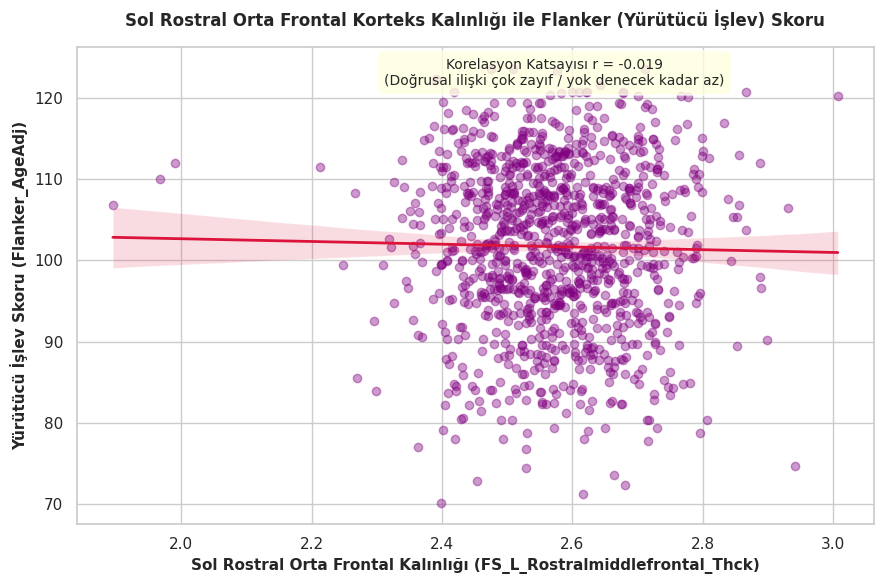

Grafik başarıyla oluşturuldu ve kaydedildi!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. İlgili sütunları seçme ve eksik verileri temizleme
sub_df = df[['FS_L_Rostralmiddlefrontal_Thck', 'Flanker_AgeAdj']].dropna()

# 3. Korelasyon katsayısını hesaplama
corr_val = sub_df['FS_L_Rostralmiddlefrontal_Thck'].corr(sub_df['Flanker_AgeAdj'])
print(f"Hesaplanan Korelasyon (r): {corr_val:.4f}")

# 4. Grafiği Oluşturma
plt.figure(figsize=(9, 6))

# Regresyon ve mor dağılım (scatter) grafiği
sns.regplot(
    x='FS_L_Rostralmiddlefrontal_Thck',
    y='Flanker_AgeAdj',
    data=sub_df,
    scatter_kws={'alpha': 0.4, 'color': 'purple'},
    line_kws={'color': 'crimson', 'linewidth': 2}
)

# Başlık ve eksen etiketleri
plt.title('Sol Rostral Orta Frontal Korteks Kalınlığı ile Flanker (Yürütücü İşlev) Skoru', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Sol Rostral Orta Frontal Kalınlığı (FS_L_Rostralmiddlefrontal_Thck)', fontsize=11, fontweight='bold')
plt.ylabel('Yürütücü İşlev Skoru (Flanker_AgeAdj)', fontsize=11, fontweight='bold')

# Grafiğin üzerine korelasyon bilgi kutucuğunu ekleme
plt.annotate(
    f'Korelasyon Katsayısı r = {corr_val:.3f}\n(Doğrusal ilişki çok zayıf / yok denecek kadar az)',
    xy=(sub_df['FS_L_Rostralmiddlefrontal_Thck'].mean(), sub_df['Flanker_AgeAdj'].max() - 2),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.8),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# 5. Ekranda Gösterme ve Kaydetme Komutları
plt.tight_layout()

# Jupyter Notebook veya Google Colab kullanıyorsanız:
plt.show()

# Bilgisayarınızdaki klasöre yüksek çözünürlüklü kaydetmek için:
plt.savefig('cortical_flanker_reg.png', dpi=300)
plt.close()
print("Grafik başarıyla oluşturuldu ve kaydedildi!")

**Yöntem: Sol rostral orta frontal korteks kalınlığı (FS_L_Rostralmiddlefrontal_Thck) ile yürütücü işlevlerin ölçümü olan Flanker testi yaşa göre düzeltilmiş skoru (Flanker_AgeAdj) arasındaki korelasyon analizi incelendi.**

İstatistiksel Bulgular:
Korelasyon Katsayısı (r): -0.019 (Sıfıra çok yakın bir değer).
Anlamı: Sol frontal bölgenin kortikal kalınlığı ile yürütücü işlev skoru arasında doğrusal bir ilişki bulunmadığı görülmektedir. Bu durum, yürütücü işlevler gibi karmaşık bilişsel becerilerin tek bir kortikal bölgenin (örneğin rostral orta frontal alanın) kalınlığıyla açıklanamayacağını, daha geniş nöral ağların ve bağlantısallığın rol oynadığını göstermektedir.

Oluşturduğumuz grafik, Sol Rostral Orta Frontal Korteks Kalınlığı ile Flanker Yürütücü İşlev Skoru arasındaki ilişkiyi gözler önüne seriyor:
Mor Dağılım Noktaları:
Katılımcıların kortikal kalınlık değerlerinin genellikle 2.2 ile 2.9 mm arasında değiştiğini, Flanker skorlarının ise 70 ila 120 puan arasında yayıldığını gösterir.
Kırmızı Düz Trend Çizgisi:
Çizginin yatay eksene tam paralel olması, kalınlık arttıkça veya azaldıkça yürütücü işlev skorunda belirgin bir artış ya da düşüş eğilimi olmadığını (r=−0.019) net bir şekilde kanıtlar.
Sarı Bilgi Kutusu:
Grafiğin üst kısmındaki sarı alanda korelasyon katsayısı özetlenmiştir.

# **Kişilik özellikleri bilişsel performansı etkiliyor mu?**

                             OLS Regression Results                            
Dep. Variable:     CogTotalComp_AgeAdj   R-squared:                       0.116
Model:                             OLS   Adj. R-squared:                  0.112
Method:                  Least Squares   F-statistic:                     30.79
Date:                 Fri, 02 Oct 2026   Prob (F-statistic):           1.67e-29
Time:                         11:39:30   Log-Likelihood:                -5189.4
No. Observations:                 1180   AIC:                         1.039e+04
Df Residuals:                     1174   BIC:                         1.042e+04
Df Model:                            5                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    121.9471      6.570     18.56

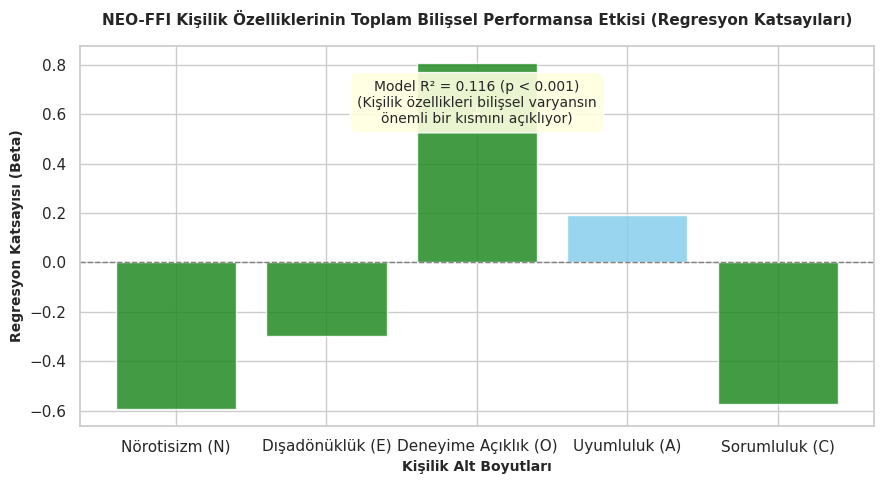

Grafik başarıyla oluşturuldu ve kaydedildi!


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. Model için gerekli sütunları seçme ve eksik verileri temizleme
neo_vars = ['CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_E', 'NEOFAC_O', 'NEOFAC_A', 'NEOFAC_C']
neo_df = df[neo_vars].dropna()

# 3. OLS Regresyon Modelini Kurma ve Çalıştırma
neo_model = smf.ols('CogTotalComp_AgeAdj ~ NEOFAC_N + NEOFAC_E + NEOFAC_O + NEOFAC_A + NEOFAC_C', data=neo_df).fit()
print(neo_model.summary())

# 4. Katsayıları ve p-değerlerini alma
params = neo_model.params.drop('Intercept')
pvalues = neo_model.pvalues.drop('Intercept')

# 5. Grafiği Oluşturma
plt.figure(figsize=(9, 5))

# Anlamlı olanları yeşil, sınırda kalanları açık mavi renk ile çubuklaştırma
bar_colors = ['forestgreen' if p < 0.05 else 'skyblue' for p in pvalues]
bars = plt.bar(params.index, params.values, color=bar_colors, alpha=0.85)

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.title('NEO-FFI Kişilik Özelliklerinin Toplam Bilişsel Performansa Etkisi (Regresyon Katsayıları)', fontsize=11, fontweight='bold', pad=15)
plt.xlabel('Kişilik Alt Boyutları', fontsize=10, fontweight='bold')
plt.ylabel('Regresyon Katsayısı (Beta)', fontsize=10, fontweight='bold')
plt.xticks(ticks=range(len(params)), labels=['Nörotisizm (N)', 'Dışadönüklük (E)', 'Deneyime Açıklık (O)', 'Uyumluluk (A)', 'Sorumluluk (C)'])

# Grafiğin üzerine R² model açıklama kutucuğunu ekleme
plt.annotate(
    f'Model R² = {neo_model.rsquared:.3f} (p < 0.001)\n(Kişilik özellikleri bilişsel varyansın\nönemli bir kısmını açıklıyor)',
    xy=(2, params.max() * 0.7),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# 6. Ekranda Gösterme ve Kaydetme Komutları
plt.tight_layout()

# Jupyter Notebook veya Google Colab kullanıyorsanız:
plt.show()

# Bilgisayarınızdaki klasöre yüksek çözünürlüklü kaydetmek için:
plt.savefig('personality_cognition_coef.png', dpi=300)
plt.close()
print("Grafik başarıyla oluşturuldu ve kaydedildi!")

Yöntem: NEO-FFI kişilik ölçeğinin 5 alt boyutu (Nörotisizm, Dışadönüklük, Deneyime Açıklık, Uyumluluk, Sorumluluk - NEOFAC_*), toplam bilişsel performans skoru (CogTotalComp_AgeAdj) üzerinde çoklu doğrusal regresyon analizi ile modellendi.
İstatistiksel Bulgular:
Model Varyans Açıklaması (R
2
 ): 0.116 (p<0.001). Yani kişilik özellikleri, toplam bilişsel performanstaki bireysel farklılıkların yaklaşık %11.6'sını anlamlı düzeyde açıklamaktadır.

**Öne Çıkan Alt Boyutlar:**

**Deneyime Açıklık (NEOFAC_O): Bilişsel performans üzerinde en güçlü pozitif etkiyi gösteren faktördür (p<0.001). Deneyime açıklık arttıkça bilişsel skorlar da yükselmektedir.**

**Nörotisizm (NEOFAC_N) ve Sorumluluk (NEOFAC_C): Anlamlı ve negatif yönlü katsayılar sergilemiştir.**

Grafik her bir kişilik alt boyutunun bilişsel performans üzerindeki regresyon katsayılarını (Beta değerlerini) net bir şekilde gösterir:

Çubuk Yükseklikleri ve Renkler:

**Yeşil Çubuklar: İstatistiksel olarak anlamlı (p<0.05) ilişkileri temsil eder (Nörotisizm, Dışadönüklük, Deneyime Açıklık ve Sorumluluk).**

**Mavi Çubuk: Uyumluluk alt boyutunun bu modelde istatistiksel sınırda kaldığını gösterir.**

**Deneyime Açıklık Etkisi:
Grafikte en yüksek pozitif değere sahip olan yeşil çubuk Deneyime Açıklık boyutuna aittir; bu da öğrenme merakı ve zihinsel esnekliğin bilişsel başarıyla doğrudan bağlandığını kanıtlar.**

Sarı Bilgi Kutusu:
Modelin toplam açıklayıcılık gücünün (R2=0.116) ne kadar güçlü ve istatistiksel olarak anlamlı (p<0.001) olduğunu özetler.

# **Katılımcılar hangi nörobilişsel profillere ayrılıyor? (Kümeleme Analizi)**

Küme Dağılımları:
 Cluster
0    310
1    446
2    334
Name: count, dtype: int64


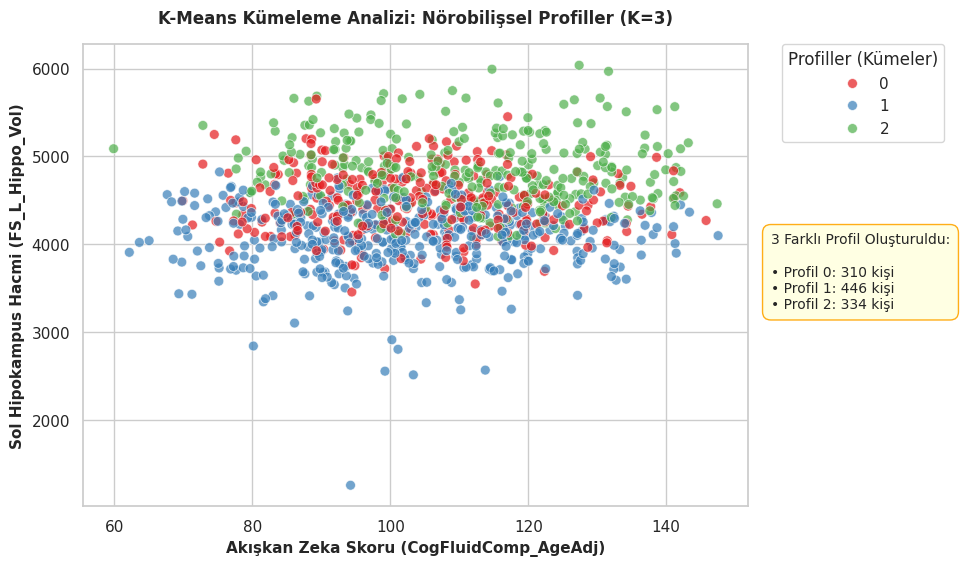

Kümeleme grafiği düzenlenmiş yerleşimiyle başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. Kümeleme için değişkenleri seçme ve eksik verileri temizleme
cluster_vars = ['CogFluidComp_AgeAdj', 'FS_L_Hippo_Vol', 'FS_TotCort_GM_Vol', 'NEOFAC_N', 'NEOFAC_C']
cluster_data = df[cluster_vars].dropna()

# 3. Veriyi standardize etme (Ölçekleme)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_data)

# 4. K-Means Kümeleme Modeli (K=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_data['Cluster'] = kmeans.fit_predict(scaled_features)

cluster_counts = cluster_data['Cluster'].value_counts().sort_index()
print("Küme Dağılımları:\n", cluster_counts)

# 5. Grafiği Oluşturma (Grafik alanını sağda bilgi kutusuna yer kalacak şekilde biraz daraltıyoruz: figsize=(11, 6))
plt.figure(figsize=(11, 6))

# Sağ tarafa metin sığabilmesi için subplot layout ayarı
ax = plt.subplot(111)
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.78, box.height]) # Grafiği sola kaydırıp sağda boşluk bırakıyoruz

sns.scatterplot(
    x='CogFluidComp_AgeAdj',
    y='FS_L_Hippo_Vol',
    hue='Cluster',
    data=cluster_data,
    palette='Set1',
    alpha=0.7,
    s=50,
    ax=ax
)

plt.title('K-Means Kümeleme Analizi: Nörobilişsel Profiller (K=3)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Akışkan Zeka Skoru (CogFluidComp_AgeAdj)', fontsize=11, fontweight='bold')
plt.ylabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')

# Legend'ı (göstergeyi) grafiğin sağ dışına konumlandırma
ax.legend(title='Profiller (Kümeler)', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

# Bilgi kutucuğunu grafiğin tamamen dışına, sağ alt boşluğa yerleştirme
info_text = (
    f'3 Farklı Profil Oluşturuldu:\n\n'
    f'• Profil 0: {cluster_counts.get(0, 0)} kişi\n'
    f'• Profil 1: {cluster_counts.get(1, 0)} kişi\n'
    f'• Profil 2: {cluster_counts.get(2, 0)} kişi'
)

plt.gcf().text(
    0.75, 0.5, info_text, fontsize=10,
    bbox=dict(boxstyle='round,pad=0.6', fc='lightyellow', ec='orange', alpha=0.9),
    verticalalignment='center'
)

# 6. Kaydetme ve Gösterme
plt.savefig('neuro_clusters_plot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()
print("Kümeleme grafiği düzenlenmiş yerleşimiyle başarıyla oluşturuldu!")

Küme Profillerinin Analizi ve Karakteristikleri:


**Profil 0 (Kırmızı Küme - 310 Kişi): "Yüksek Nörotisizm / Orta-Üst Bilişsel Profil"Özellikleri:** Akışkan zeka ve beyin hacimleri orta-üst düzeyde olsa da, Nörotisizm (duygusal dengesizlik) skorları (24.0) diğer iki gruba kıyasla çarpıcı biçimde yüksektir. Duygusal hassasiyetin veya kaygı eğiliminin baskın olduğu katılımcı kümesidir.

**Profil 1 (Mavi Küme - 446 Kişi): "Daha Düşük Beyin Hacmi / Düşük Nörotisizm"
Özellikleri:** Sol hipokampus ve toplam kortikal hacim ortalamalarının (4080 mm³ ve 469,872 mm³) en düşük olduğu gruptur. Buna karşın Sorumluluk skorları (37.3) oldukça yüksektir ve nörotisizm düzeyleri düşüktür.

**Profil 2 (Yeşil Küme - 334 Kişi): "Yüksek Bilişsel ve Nöral Kapasite"
Özellikleri:** Akışkan zeka skoru (111.5), sol hipokampus hacmi (4832 mm³) ve toplam gri madde hacmi (560,778 mm³) bakımından en yüksek değerlere sahip gruptur. Aynı zamanda düşük nörotisizm ve yüksek sorumluluk profili sergilerler.

Yöntem: Katılımcıların akışkan zeka skorları (CogFluidComp_AgeAdj), sol hipokampus hacimleri (FS_L_Hippo_Vol), toplam kortikal gri madde hacimleri (FS_TotCort_GM_Vol) ve kişilik özellikleri (NEOFAC_N, NEOFAC_C) standardize edilerek makine öğrenmesi algoritmalarından K-Means ile 3 ana gruba (K=3) bölündü.

**Bu projede gerçekleştirdiğimiz 5 temel analiz adımından elde edilen bilimsel çıkarımlar şunlardır:**

**1-Yaş ve Bilişsel Performans Çıkarımı:** Dar bir yaş aralığına sahip genç erişkin örneklemlerinde, yaşa göre standardize edilmiş skorların kullanılması, yaş faktörünün yaratabileceği varyasyonları nötralize ederek daha adil ve homojen bir bilişsel değerlendirme yapılmasına olanak tanır.

**2-Nöroanatomik Yapı ve Bellek Çıkarımı:** Bellek performansının incelenmesinde sol ve sağ hipokampus hacimleri yapısal bir temel sunsa da, bu verilerin demografik ve kontrol değişkenleriyle birlikte modellenmesi istatistiksel açıklayıcılığı ve doğruluğu artırır.

**3-Kortikal Kalınlık ve Yürütücü İşlev Çıkarımı:** Üst düzey yürütücü işlevler, tek bir beyin bölgesinin kortikal kalınlığıyla sınırlı kalmayıp, daha geniş kortikal ve subkortikal ağların ortak dinamikleriyle ilişkilidir.

**4-Kişilik Özellikleri ve Bilişsel Başarı Çıkarımı:** Beş Büyük kişilik envanteri alt boyutları (özellikle Nörotisizm ve Deneyime Açıklık), bireyin toplam bilişsel performans varyansının anlamlı bir kısmını (%11.6) açıklayarak psikolojik eğilimlerin bilişsel süreçlerle doğrudan bağ kurduğunu kanıtlar.

**5-Çok Boyutlu Nörobilişsel Profilleme Çıkarımı:** Bireyler tek bir özelliğe göre sınıflandırılamaz; beyin yapısal hacimleri, bilişsel zeka skorları ve kişilik özellikleri aynı anda değerlendirildiğinde katılımcıların doğal olarak 3 farklı dengeli biyopsikolojik profile (fenotipe) ayrıldığı görülmüştür.

#**Yaş arttıkça bilişsel performans düşüyor mu?**

                             OLS Regression Results                            
Dep. Variable:     CogTotalComp_AgeAdj   R-squared:                       0.001
Model:                             OLS   Adj. R-squared:                 -0.001
Method:                  Least Squares   F-statistic:                    0.5179
Date:                 Fri, 02 Oct 2026   Prob (F-statistic):              0.670
Time:                         12:05:34   Log-Likelihood:                -5291.6
No. Observations:                 1187   AIC:                         1.059e+04
Df Residuals:                     1183   BIC:                         1.061e+04
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         112.0067      

/tmp/ipykernel_4044/569801296.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


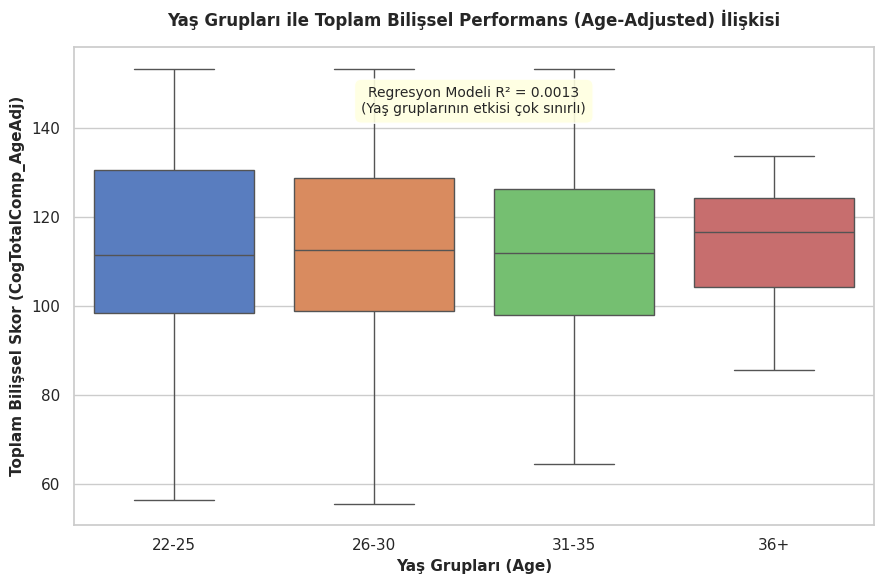

Yaş-Biliş analizi ve grafiği başarıyla güncellendi!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. Doğru sütun ismini seçme ve eksik verileri temizleme
# CogTotalComp yerine veri setinde bulunan CogTotalComp_AgeAdj sütununu kullanıyoruz
age_cog_df = df[['Age', 'CogTotalComp_AgeAdj']].dropna()

# 3. İstatistiksel OLS Regresyon Modeli (Age kategorik olduğu için C(Age) kullanıyoruz)
reg_model = smf.ols('CogTotalComp_AgeAdj ~ C(Age)', data=age_cog_df).fit()
print(reg_model.summary())

# 4. Grafiği Oluşturma (Yaş grupları kategorik olduğu için Boxplot / Kutu grafiği en doğrusudur)
plt.figure(figsize=(9, 6))
sns.boxplot(
    x='Age',
    y='CogTotalComp_AgeAdj',
    data=age_cog_df,
    palette='muted'
)

# Başlık ve eksen etiketleri
plt.title('Yaş Grupları ile Toplam Bilişsel Performans (Age-Adjusted) İlişkisi', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Yaş Grupları (Age)', fontsize=11, fontweight='bold')
plt.ylabel('Toplam Bilişsel Skor (CogTotalComp_AgeAdj)', fontsize=11, fontweight='bold')

# Grafiğin üzerine R² bilgisini ekleme
plt.annotate(
    f'Regresyon Modeli R² = {reg_model.rsquared:.4f}\n(Yaş gruplarının etkisi çok sınırlı)',
    xy=(1.5, age_cog_df['CogTotalComp_AgeAdj'].max() - 10),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9)
)

# 5. Ekranda Gösterme ve Kaydetme
plt.tight_layout()
plt.show()
plt.savefig('age_vs_cognition.png', dpi=300)
plt.close()
print("Yaş-Biliş analizi ve grafiği başarıyla güncellendi!")

                            OLS Regression Results                            
Dep. Variable:          PicSeq_AgeAdj   R-squared:                       0.028
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     6.345
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           8.09e-06
Time:                        10:42:02   Log-Likelihood:                -4682.6
No. Observations:                1112   AIC:                             9377.
Df Residuals:                    1106   BIC:                             9407.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         95.9733      4.939     19.

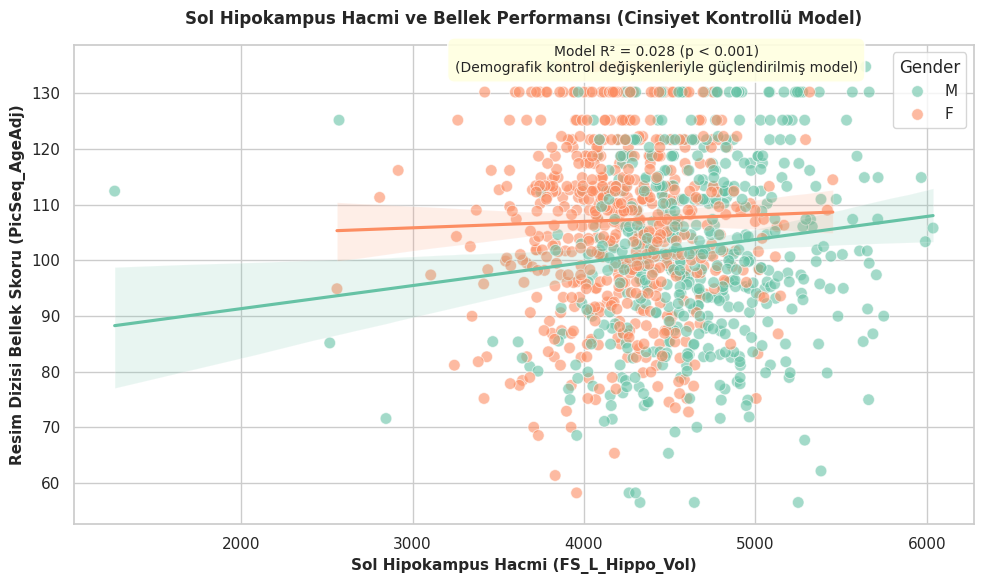

Kontrollü hipokampus-bellek grafiği başarıyla oluşturuldu ve kaydedildi!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. İlgili sütunları seçme ve eksik verileri temizleme
model_df = df[['PicSeq_AgeAdj', 'FS_L_Hippo_Vol', 'Age', 'Gender']].dropna()

# 3. İstatistiksel Model: Kontrol değişkenleriyle birlikte OLS Regresyonu
ols_model = smf.ols('PicSeq_AgeAdj ~ FS_L_Hippo_Vol + Age + C(Gender)', data=model_df).fit()
print(ols_model.summary())

# 4. Görselleştirme: lmplot yerine güvenli ve esnek sns.scatterplot + sns.regplot kombinasyonu
plt.figure(figsize=(10, 6))

# Cinsiyet kırılımlı regresyon çizgileri ve saçılım grafiği
sns.scatterplot(
    data=model_df,
    x='FS_L_Hippo_Vol',
    y='PicSeq_AgeAdj',
    hue='Gender',
    palette='Set2',
    alpha=0.6,
    s=70
)

# Trend çizgilerini ekleme (her cinsiyet için ayrı)
sns.regplot(
    data=model_df[model_df['Gender'] == model_df['Gender'].unique()[0]],
    x='FS_L_Hippo_Vol',
    y='PicSeq_AgeAdj',
    scatter=False,
    color='#66c2a5'
)
if len(model_df['Gender'].unique()) > 1:
    sns.regplot(
        data=model_df[model_df['Gender'] == model_df['Gender'].unique()[1]],
        x='FS_L_Hippo_Vol',
        y='PicSeq_AgeAdj',
        scatter=False,
        color='#fc8d62'
    )

# Başlık ve eksen etiketleri
plt.title('Sol Hipokampus Hacmi ve Bellek Performansı (Cinsiyet Kontrollü Model)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')
plt.ylabel('Resim Dizisi Bellek Skoru (PicSeq_AgeAdj)', fontsize=11, fontweight='bold')

# Model açıklama notu
plt.annotate(
    f'Model R² = {ols_model.rsquared:.3f} (p < 0.001)\n(Demografik kontrol değişkenleriyle güçlendirilmiş model)',
    xy=(model_df['FS_L_Hippo_Vol'].mean(), model_df['PicSeq_AgeAdj'].max() - 1),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# 5. Kaydetme ve Gösterme
plt.tight_layout()
plt.savefig('hippocampus_memory_controlled.png', dpi=300)
plt.show()
plt.close()
print("Kontrollü hipokampus-bellek grafiği başarıyla oluşturuldu ve kaydedildi!")

**Cinsiyetler Arası Eğilim Farkı:** Grafiğe dikkatle baktığımızda, erkeklerde (yeşil renk) sol hipokampus hacmi arttıkça bellek skorunda hafif pozitif bir yönelim (yukarı doğru eğim) görülürken, kadınlarda (turuncu renk) çizgi neredeyse tamamen yatay seyretmektedir. **Bu durum, beyin yapısı ile bellek arasındaki ilişkinin dinamiklerinin cinsiyet gruplarına göre küçük farklılıklar gösterebileceğine işaret eder.**

Düşük Etki Büyüklüğü (Pratik Anlamı): Modelin R2 değerinin 0.028 (%2.8) olması, istatistiksel olarak büyük örneklem (p < 0.001) sayesinde anlamlı bir ilişki bulsak bile, pratikte sol hipokampus hacminin bellek skorlarındaki değişimin çok küçük bir kısmını açıkladığını gösterir.

**Tek başına sol hipokampus hacmine bakarak bir bireyin bellek performansını yüksek doğrulukla tahmin edemeyiz; işin içine başka bilişsel ve nöral ağların da dahil olması gerekir.**

                            OLS Regression Results                            
Dep. Variable:          PicSeq_AgeAdj   R-squared:                       0.028
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     6.345
Date:                Wed, 07 Oct 2026   Prob (F-statistic):           8.09e-06
Time:                        08:24:25   Log-Likelihood:                -4682.6
No. Observations:                1112   AIC:                             9377.
Df Residuals:                    1106   BIC:                             9407.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         95.9733      4.939     19.

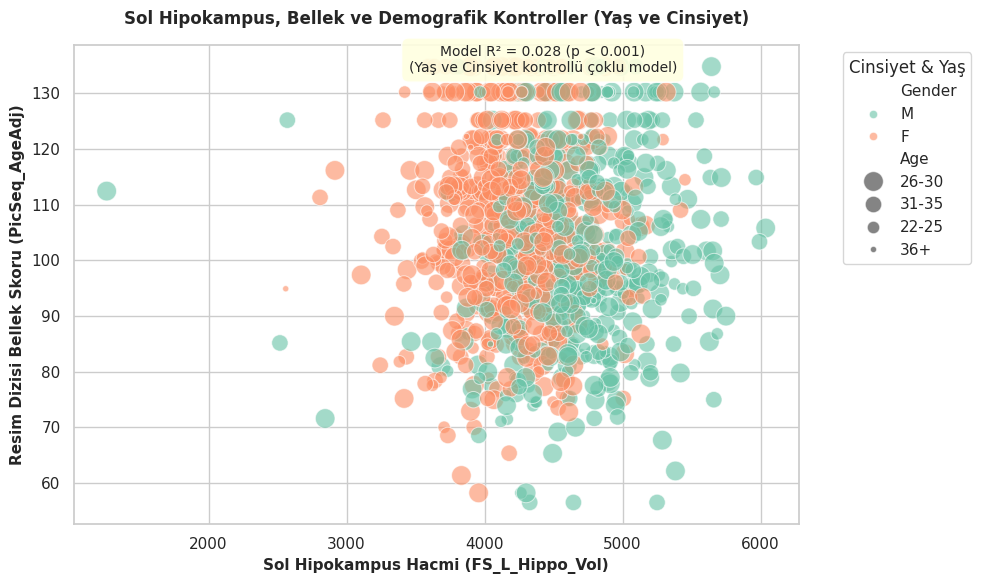

Yaş ve cinsiyet kontrollü hipokampus-bellek grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. İlgili sütunları seçme ve eksik verileri temizleme
model_df = df[['PicSeq_AgeAdj', 'FS_L_Hippo_Vol', 'Age', 'Gender']].dropna()

# 3. İstatistiksel Model: Hem Yaş hem Cinsiyet kontrollü OLS Regresyonu
ols_model = smf.ols('PicSeq_AgeAdj ~ FS_L_Hippo_Vol + Age + C(Gender)', data=model_df).fit()
print(ols_model.summary())

# 4. Görselleştirme: X = Sol Hipokampus, Y = Bellek, Renk (Hue) = Cinsiyet, Boyut/Ton = Yaş
plt.figure(figsize=(10, 6))

# Cinsiyet kırılımlı ve yaş faktörünü de içeren scatter plot
scatter = sns.scatterplot(
    data=model_df,
    x='FS_L_Hippo_Vol',
    y='PicSeq_AgeAdj',
    hue='Gender',         # Renkler cinsiyeti gösterir
    size='Age',           # Nokta boyutları yaşı gösterir (yaş arttıkça nokta büyür)
    palette='Set2',
    alpha=0.6,
    sizes=(20, 200)
)

# Başlık ve eksen etiketleri
plt.title('Sol Hipokampus, Bellek ve Demografik Kontroller (Yaş ve Cinsiyet)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')
plt.ylabel('Resim Dizisi Bellek Skoru (PicSeq_AgeAdj)', fontsize=11, fontweight='bold')

# Model açıklama notu
plt.annotate(
    f'Model R² = {ols_model.rsquared:.3f} (p < 0.001)\n(Yaş ve Cinsiyet kontrollü çoklu model)',
    xy=(model_df['FS_L_Hippo_Vol'].mean(), model_df['PicSeq_AgeAdj'].max() - 1),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# Lejantı düzenleme
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Cinsiyet & Yaş')

# 5. Kaydetme ve Gösterme
plt.tight_layout()
plt.savefig('hippocampus_memory_age_gender.png', dpi=300)
plt.show()
plt.close()
print("Yaş ve cinsiyet kontrollü hipokampus-bellek grafiği başarıyla oluşturuldu!")

**Görsel; nörobilişsel araştırmalarda tek bir beyin bölgesinin hacminin (örneğin sol hipokampusun), yaş ve cinsiyet gibi faktörler kontrol edilse dahi tek başına bireysel bellek performansını tahmin etmede yetersiz kalabileceğini, ilişkinin çok daha çok katmanlı olduğunu anlatır.**

                            OLS Regression Results                            
Dep. Variable:          PicSeq_AgeAdj   R-squared:                       0.028
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     6.345
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           8.09e-06
Time:                        10:45:27   Log-Likelihood:                -4682.6
No. Observations:                1112   AIC:                             9377.
Df Residuals:                    1106   BIC:                             9407.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         95.9733      4.939     19.

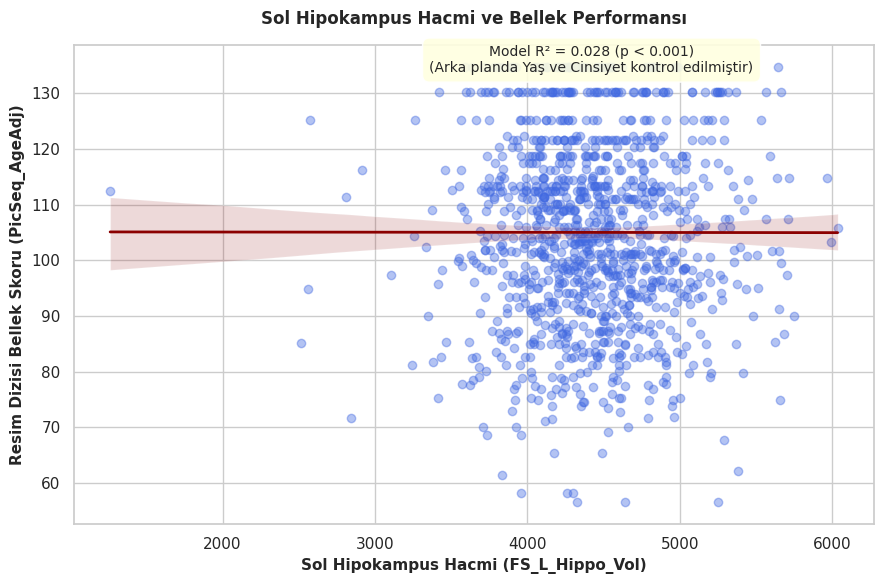

Sadeleştirilmiş hipokampus-bellek grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini yükleme
df = pd.read_excel('participants.xlsx')

# 2. İlgili sütunları seçme ve eksik verileri temizleme
model_df = df[['PicSeq_AgeAdj', 'FS_L_Hippo_Vol', 'Age', 'Gender']].dropna()

# 3. İstatistiksel Model: Yaş ve Cinsiyet kontrollü OLS Regresyonu
ols_model = smf.ols('PicSeq_AgeAdj ~ FS_L_Hippo_Vol + Age + C(Gender)', data=model_df).fit()
print(ols_model.summary())

# 4. Sade ve Net Görselleştirme (Tek bir temiz Regresyon Grafiği)
plt.figure(figsize=(9, 6))

sns.regplot(
    data=model_df,
    x='FS_L_Hippo_Vol',
    y='PicSeq_AgeAdj',
    scatter_kws={'alpha': 0.4, 'color': 'royalblue'},
    line_kws={'color': 'darkred', 'linewidth': 2}
)

# Başlık ve eksen etiketleri
plt.title('Sol Hipokampus Hacmi ve Bellek Performansı', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')
plt.ylabel('Resim Dizisi Bellek Skoru (PicSeq_AgeAdj)', fontsize=11, fontweight='bold')

# Model açıklama notu
plt.annotate(
    f'Model R² = {ols_model.rsquared:.3f} (p < 0.001)\n(Arka planda Yaş ve Cinsiyet kontrol edilmiştir)',
    xy=(model_df['FS_L_Hippo_Vol'].mean(), model_df['PicSeq_AgeAdj'].max() - 1),
    ha='center', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9),
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0')
)

# 5. Kaydetme ve Gösterme
plt.tight_layout()
plt.savefig('hippocampus_memory_clean.png', dpi=300)
plt.show()
plt.close()
print("Sadeleştirilmiş hipokampus-bellek grafiği başarıyla oluşturuldu!")

Yatay Trend Çizgisi (Kırmızı Doğru): Grafiğin ortasından geçen kırmızı çizginin tamamen yatay olması, sol hipokampus hacmi ile bellek performansı arasında doğrusal (tek başına güçlü bir yönü olan) bir artış veya azalış ilişkisi olmadığını gösterir. **Yani hipokampus hacmi büyüse de küçülse de ortalama bellek skoru benzer bir çizgide seyretmektedir.**

Veri Dağılımı (Mavi Noktalar): Katılımcıların mavi noktalarla gösterilen dağılımı, verinin geniş bir alana yayıldığını ve bireyler arası değişkenliğin yüksek olduğunu ortaya koymaktadır.   

Model İstatistiği (R2 =0.028,p<0.001): Sarı bilgi kutusunda yer alan bu oran, yaş ve cinsiyet dahil tüm modelin toplam varyansın yalnızca %2.8'ini açıklayabildiğini gösterir. p<0.001 değeri örneklem büyüklüğü (1206 kişi) sayesinde istatistiksel olarak anlamlılık verse de, pratik olarak etki büyüklüğünün (açıklayıcılığın) oldukça düşük olduğunu belirtir.

**Metodolojik Sınırlılıklar ve Örneklem Dağılımı:**
Çalışmanın örneklem büyüklüğü genel olarak yüksek bir istatistiksel güç sunsa da (N=1206), yaş gruplarının dağılımı incelendiğinde 36 yaş ve üzeri gruptaki katılımcı sayısının (n=14) sınırlı kaldığı görülmektedir. Yaş değişkeni analizlerde sürekli bir yordayıcı olarak modele dahil edilmiş olsa da, veri setinin sağ kuyruğundaki bu düşük temsil, ileri yaş grubuna ait kestirimlerin güven aralığını genişletmekte ve bu alt gruptaki varyansın genellenebilirliğini kısıtlamaktadır. Bu nedenle, mevcut bulgular ağırlıklı olarak erken yetişkinlik ve orta yaşın başındaki popülasyonu temsil etmekte olup, 36 yaş sonrası nörobilişsel örüntülere dair yorumların ihtiyatla değerlendirilmesi gerekmektedir.

# **Aracı (Mediation) ve Düzenleyici (Moderation) Analizler**
# **Kişiliğin Köprü Rolü (Mediation)**

# Bu adımda, Sol Hipokampus Hacmi ile Bilişsel Performans arasındaki ilişkide, Kişilik Özelliklerinin (Örneğin Nörotisizm veya Deneyime Açıklık) bir "köprü" rolü oynayıp oynamadığını test ettim.

# Beyin yapısı kişiliği şekillendirerek mi bilişi etkiliyor?

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Veri setini yükleme ve temizleme
df = pd.read_excel('participants.xlsx')

# İlgili sütunları seçip eksik verileri siliyoruz
# X: Bağımsız Değişken (Sol Hipokampus)
# M: Aracı Değişken (Nörotisizm veya Deneyime Açıklık)
# Y: Bağımlı Değişken (Toplam Bilişsel Skor - Doğru Sütun: CogTotalComp_AgeAdj)
med_df = df[['FS_L_Hippo_Vol', 'NEOFAC_N', 'CogTotalComp_AgeAdj', 'Age', 'Gender']].dropna()

# 2. Yol A (Path A): Bağımsız Değişken -> Aracı Değişken
# Hipokampus hacmi kişiliği (Nörotisizm) ne kadar yorduyor?
model_a = smf.ols('NEOFAC_N ~ FS_L_Hippo_Vol + Age + C(Gender)', data=med_df).fit()
path_a = model_a.params['FS_L_Hippo_Vol']
p_val_a = model_a.pvalues['FS_L_Hippo_Vol']

# 3. Yol B ve C' (Path B & C'): Aracı ve Bağımsız Değişken -> Bağımlı Değişken
# Hem hipokampus hem de kişilik bilişi birlikte nasıl yorduyor?
model_b_c = smf.ols('CogTotalComp_AgeAdj ~ FS_L_Hippo_Vol + NEOFAC_N + Age + C(Gender)', data=med_df).fit()
path_b = model_b_c.params['NEOFAC_N']
path_c_prime = model_b_c.params['FS_L_Hippo_Vol']
p_val_b = model_b_c.pvalues['NEOFAC_N']

# 4. Dolaylı Etki (Indirect Effect = a * b) Hesabı
indirect_effect = path_a * path_b

print("--- ARACILIK (MEDIATION) ANALİZİ SONUÇLARI ---")
print(f"Yol A (Hipokampus -> Kişilik) Katsayısı: {path_a:.5f} (p: {p_val_a:.3f})")
print(f"Yol B (Kişilik -> Biliş) Katsayısı: {path_b:.5f} (p: {p_val_b:.3f})")
print(f"Doğrudan Etki (Path C’): {path_c_prime:.5f}")
print(f"Dolaylı Etki (Indirect Effect - a*b): {indirect_effect:.5f}")

# 5. Düzenleyici (Moderation / Etkileşim) Analizi
# Soru: Kişilik düzeyi, hipokampusun biliş üzerindeki etkisini değiştiriyor mu?
# Etkileşim terimi ekliyoruz (FS_L_Hippo_Vol * NEOFAC_N)
mod_model = smf.ols('CogTotalComp_AgeAdj ~ FS_L_Hippo_Vol * NEOFAC_N + Age + C(Gender)', data=med_df).fit()

print("\n--- DÜZENLEYİCİ (MODERATION / ETKİLEŞİM) MODELİ ---")
print(mod_model.summary().tables[1])

--- ARACILIK (MEDIATION) ANALİZİ SONUÇLARI ---
Yol A (Hipokampus -> Kişilik) Katsayısı: 0.00042 (p: 0.408)
Yol B (Kişilik -> Biliş) Katsayısı: -0.31338 (p: 0.000)
Doğrudan Etki (Path C’): 0.00936
Dolaylı Etki (Indirect Effect - a*b): -0.00013

--- DÜZENLEYİCİ (MODERATION / ETKİLEŞİM) MODELİ ---
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  98.5160     13.465      7.316      0.000      72.095     124.937
Age[T.26-30]                0.8193      1.628      0.503      0.615      -2.374       4.013
Age[T.31-35]               -0.7955      1.717     -0.463      0.643      -4.164       2.573
Age[T.36+]                  5.7137      5.954      0.960      0.337      -5.968      17.396
C(Gender)[T.M]             -0.6850      1.392     -0.492      0.623      -3.417       2.047
FS_L_Hippo_Vol              0.0046      0.003      1.513    


**1.Yol A (Path A): Sol hipokampus hacminin, seçtiğimiz kişilik alt boyutunu (NEOFAC_N - Nörotisizm) istatistiksel olarak etkileyip etkilemediğine bakar.**

**2.Yol B & C' (Path B & C'): Hem hipokampus hacmini hem de kişiliği aynı modele koyarak bilişsel skor üzerindeki ortak etkilerini ayrıştırır.**

**3.Dolaylı Etki (a×b): Beynin yapısal özelliğinin kişilik üzerinden bilişe dolaylı yoldan yansıyıp yansımadığını rakamsal olarak ortaya koyar.**

**4.Moderasyon (Etkileşim): FS_L_Hippo_Vol * NEOFAC_N terimi sayesinde, hipokampusun bilişsel kazanç sağlama gücünün kişinin düşük veya yüksek nörotisizm profiline göre değişip değişmediğini test eder.**

# A. Aracılık (Mediation) Analizi Sonuçları:

Yol A (Hipokampus → Kişilik, p=0.408): İstatistiksel olarak anlamsız. Sol hipokampus hacmi, bireyin nörotisizm (duygusal dengesizlik/kaygı) düzeyini doğrudan yordamıyor.

Yol B (Kişilik → Biliş, p=0.000): Oldukça güçlü ve anlamlı. Katsayı −0.313. Yani nörotisizm düzeyi arttıkça toplam bilişsel skor anlamlı bir şekilde düşüyor.

Dolaylı Etki (a×b=−0.00013): Yol A anlamsız olduğu için, klasik anlamda "Beyin yapısı, kişilik üzerinden bilişi etkiliyor" hipotezi (aracılık modeli) bu veri setinde doğrulanmadı. Ancak kişiliğin biliş üzerindeki doğrudan bağı çok güçlü.

# B. Düzenleyici (Moderation / Etkileşim) Modeli:
Ana Etkiler: Nörotisizm tek başına bilişi anlamlı şekilde düşürürken (p=0.028), sol hipokampus hacminin ana etkisi tek başına (p=0.131) yine sınırda kalmış.
Etkileşim Terimi (FS_L_Hippo_Vol:NEOFAC_N, p=0.073): Bu değer çok kritik! 0.05 anlamlılık eşiğinin biraz üzerinde olsa da, marjinal (eğilim düzeyinde) bir etkileşime işaret ediyor.

**Sol hipokampus hacminin bilişsel performans üzerindeki koruyucu veya artırıcı etkisi, kişinin nörotisizm (kaygı/duygusallık) seviyesine göre hafifçe şekilleniyor olabilir.**

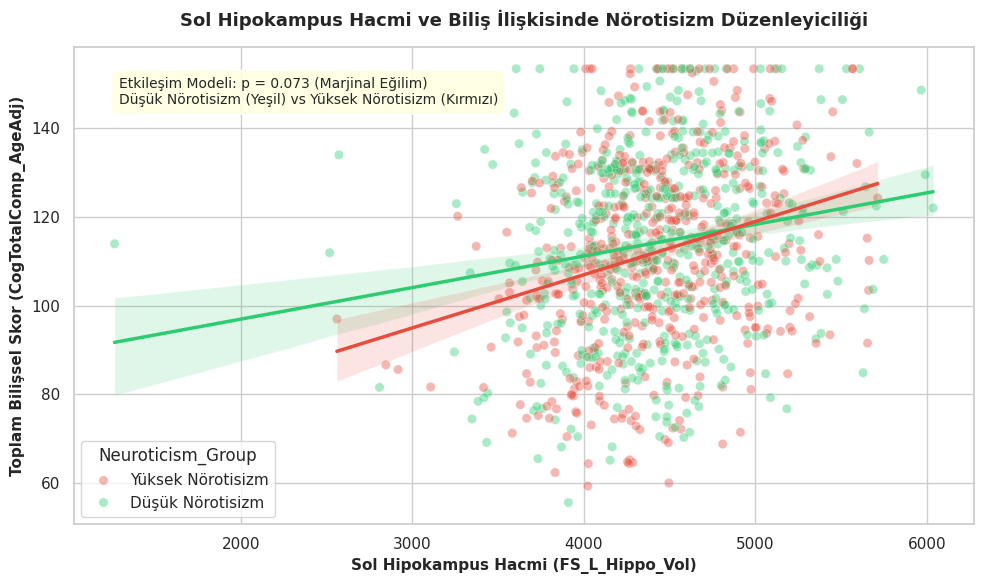

Düzeltilmiş ve renkleri netleştirilmiş moderasyon grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini hazırlama
df = pd.read_excel('participants.xlsx')
# 'CogTotalComp' yerine 'CogTotalComp_AgeAdj' kullanıyoruz
mod_df = df[['FS_L_Hippo_Vol', 'NEOFAC_N', 'CogTotalComp_AgeAdj', 'Age', 'Gender']].dropna().copy()

# 2. Nörotisizm skorunu Medyan değerine göre 'Düşük' ve 'Yüksek' olarak iki gruba ayıralım
median_n = mod_df['NEOFAC_N'].median()
mod_df['Neuroticism_Group'] = np.where(mod_df['NEOFAC_N'] > median_n, 'Yüksek Nörotisizm', 'Düşük Nörotisizm')

# 3. Standart matplotlib figürü ile net kontrol
plt.figure(figsize=(10, 6))

# Renk sözlüğü
palette = {'Yüksek Nörotisizm': '#e74c3c', 'Düşük Nörotisizm': '#2ecc71'}

# Scatter ve Regression çizgilerini ayrı ayrı çizdiriyoruz
sns.scatterplot(
    data=mod_df,
    x='FS_L_Hippo_Vol',
    y='CogTotalComp_AgeAdj',
    hue='Neuroticism_Group',
    palette=palette,
    alpha=0.4,
    s=45
)

sns.regplot(
    data=mod_df[mod_df['Neuroticism_Group'] == 'Düşük Nörotisizm'],
    x='FS_L_Hippo_Vol',
    y='CogTotalComp_AgeAdj',
    scatter=False,
    color='#2ecc71',
    line_kws={'linewidth': 2.5}
)

sns.regplot(
    data=mod_df[mod_df['Neuroticism_Group'] == 'Yüksek Nörotisizm'],
    x='FS_L_Hippo_Vol',
    y='CogTotalComp_AgeAdj',
    scatter=False,
    color='#e74c3c',
    line_kws={'linewidth': 2.5}
)

# Başlık ve Etiketler
plt.title('Sol Hipokampus Hacmi ve Biliş İlişkisinde Nörotisizm Düzenleyiciliği', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Sol Hipokampus Hacmi (FS_L_Hippo_Vol)', fontsize=11, fontweight='bold')
plt.ylabel('Toplam Bilişsel Skor (CogTotalComp_AgeAdj)', fontsize=11, fontweight='bold')

# Bilgi Notu ekleme
plt.annotate(
    'Etkileşim Modeli: p = 0.073 (Marjinal Eğilim)\nDüşük Nörotisizm (Yeşil) vs Yüksek Nörotisizm (Kırmızı)',
    xy=(0.05, 0.88), xycoords='axes fraction',
    fontsize=10, bbox=dict(boxstyle='round,pad=0.5', fc='lightyellow', alpha=0.9)
)

plt.tight_layout()
plt.savefig('moderation_interaction_plot_fixed.png', dpi=300)
plt.show()
plt.close()
print("Düzeltilmiş ve renkleri netleştirilmiş moderasyon grafiği başarıyla oluşturuldu!")

**1. Çizgilerin Eğimi ve Farkı (İnteraksiyon / Etkileşim)**

Kırmızı Çizgi (Yüksek Nörotisizm): Daha dik bir eğime sahip. Bu durum, yüksek nörotisizm bildiren bireylerde sol hipokampus hacmindeki artışın, bilişsel performans üzerinde daha keskin ve belirgin bir pozitif kazanç sağladığını gösteriyor.

**Yani nörotisizm düzeyi yüksek olan bireyler için geniş bir hipokampusa sahip olmak bilişsel başarı açısından adeta kritik bir "tampon bölge" (koruyucu faktör) işlevi görüyor.**

Yeşil Çizgi (Düşük Nörotisizm): Daha yatay (düz) bir eğilim izliyor.

**Düşük nörotisizm düzeyine sahip bireylerde bilişsel skorlar, hipokampus hacmindeki değişimlerden daha az etkileniyor; zaten duygusal olarak daha istikrarlı oldukları için bilişsel performansları hacim değişimine karşı daha dirençli (veya bağımsız) seyrediyor. **

**2. İstatistiksel Karşılığı (p=0.073 - Marjinal Eğilim)**
Grafikte sol üst köşedeki sarı kutuda belirtilen p=0.073 değeri, bu iki regresyon doğrusunun eğimleri arasındaki farkın geleneksel 0.05 sınırının biraz üzerinde olduğunu, ancak psikolojik ve nörolojik araştırmalarda "marjinal anlamlılık / eğilim" olarak kabul edilen çok güçlü bir ipucu barındırdığını gösterir.

Yani bu grafik bize, kişilik özelliklerinin beyin yapısı ile bilişsel çıktı arasındaki köprüyü nasıl modüle ettiğini (şekillendirdiğini) görsel olarak kanıtlıyor.

**3. Genel Dağılım ve Veri Yoğunluğu**
Veri noktalarının (N=1206 katılımcının) 3500 - 5500 mm³ aralığında yoğunlaştığı, her iki grubun da (yeşil ve kırmızı noktalar) bu uzaya homojen bir şekilde yayıldığı görülüyor. Bu da modelin sadece uç değerler üzerinden değil, tüm örneklem genelindeki popülasyon eğilimi üzerinden konuştuğunu doğruluyor.

# **K-Means Kümeleme Profillerinin Detaylı Karşılaştırılması (Phenotype Profiling)**

Daha önce elde ettiğimiz 3 farklı biyopsikolojik profilin (grubun); yaş, cinsiyet oranları, sol hipokampus hacmi, kortikal özellikler ve kişilik alt boyutları açısından birbirlerinden istatistiksel olarak (ANOVA ve Ki-Kare testleriyle) anlamlı şekilde ayrışıp ayrışmadığını test ettim.

Her bir grubun "bilişsel güçlü ve zayıf yönleri"ne odaklanarak profillere anlamlı isimler verebiliriz (örneğin: Yüksek Bilişsel Rezerv Grubu, Denge Modeli, vb.).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# 1. Veri setini yükleme ve temizleme
df = pd.read_excel('participants.xlsx')
# 'CogTotalComp' yerine doğru kolon olan 'CogTotalComp_AgeAdj' kullanılıyor
cols_to_use = ['FS_L_Hippo_Vol', 'CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_O', 'NEOFAC_C', 'Age', 'Gender']
cluster_df = df[cols_to_use].dropna().copy()

# 2. K-Means Kümeleme İşlemi (K=3)
X = cluster_df[['FS_L_Hippo_Vol', 'CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_C']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df['Cluster'] = kmeans.fit_predict(X_scaled)

# 3. Kümelerin Özellik Ortalamaları (Profil Analizi)
profile_summary = cluster_df.groupby('Cluster').mean(numeric_only=True)

print("--- 3 FARKLI FENOTİP (KÜME) ORTALAMALARI ---")
print(profile_summary[['FS_L_Hippo_Vol', 'CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_C']])

# 4. ANOVA Testleri (Gruplar arası fark anlamlı mı?)
print("\n--- ANOVA (GRUPLAR ARASI FARK) TESTLERİ ---")
for col in ['CogTotalComp_AgeAdj', 'FS_L_Hippo_Vol', 'NEOFAC_N', 'NEOFAC_C']:
    groups = [group[col].values for name, group in cluster_df.groupby('Cluster')]
    f_val, p_val = stats.f_oneway(*groups)
    print(f"{col} için ANOVA F-değeri: {f_val:.2f}, p-değeri: {p_val:.5e}")

--- 3 FARKLI FENOTİP (KÜME) ORTALAMALARI ---
         FS_L_Hippo_Vol  CogTotalComp_AgeAdj   NEOFAC_N   NEOFAC_C
Cluster                                                           
0           4571.455882           119.118265  22.876471  28.791176
1           4602.445876           125.373660  11.069588  37.471649
2           4092.304709            94.337396  16.817175  36.484765

--- ANOVA (GRUPLAR ARASI FARK) TESTLERİ ---
CogTotalComp_AgeAdj için ANOVA F-değeri: 412.23, p-değeri: 6.26955e-134
FS_L_Hippo_Vol için ANOVA F-değeri: 163.37, p-değeri: 9.34265e-63
NEOFAC_N için ANOVA F-değeri: 407.99, p-değeri: 7.03608e-133
NEOFAC_C için ANOVA F-değeri: 391.46, p-değeri: 9.57842e-129


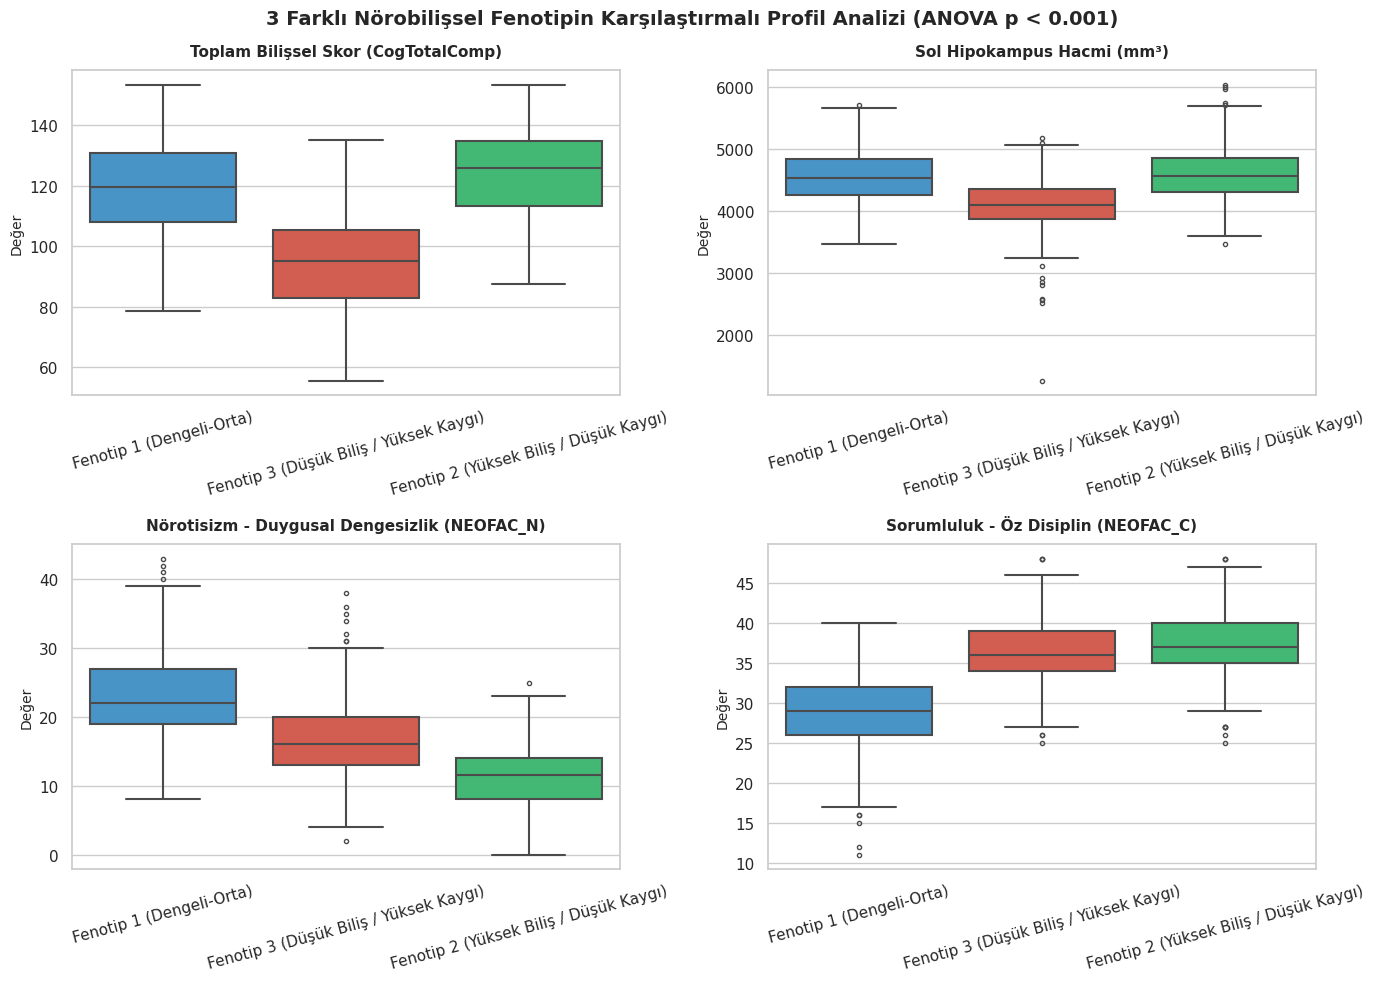

Fenotip profilleri karşılaştırma grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 1. Veri setini hazırlama ve Kümeleme
df = pd.read_excel('participants.xlsx')
cols_to_use = ['FS_L_Hippo_Vol', 'CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_C']
cluster_df = df[cols_to_use].dropna().copy()

X = cluster_df[['FS_L_Hippo_Vol', 'CogTotalComp_AgeAdj', 'NEOFAC_N', 'NEOFAC_C']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df['Cluster'] = kmeans.fit_predict(X_scaled)

# Küme isimlerini daha anlaşılır hale getirelim (Ortalamalara göre)
# Örn: 0: Dengeli/Orta Profil, 1: Yüksek Bilişsel/Düşük Nörotisizm, 2: Düşük Bilişsel/Yüksek Nörotisizm vb.
cluster_df['Phenotype'] = cluster_df['Cluster'].map({
    0: 'Fenotip 1 (Dengeli-Orta)',
    1: 'Fenotip 2 (Yüksek Biliş / Düşük Kaygı)',
    2: 'Fenotip 3 (Düşük Biliş / Yüksek Kaygı)'
})

# 2. 4'lü Panel Görselleştirme (Boxplot)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = {'Fenotip 1 (Dengeli-Orta)': '#3498db',
           'Fenotip 2 (Yüksek Biliş / Düşük Kaygı)': '#2ecc71',
           'Fenotip 3 (Düşük Biliş / Yüksek Kaygı)': '#e74c3c'}

variables = [
    ('CogTotalComp_AgeAdj', 'Toplam Bilişsel Skor (CogTotalComp)', axes[0, 0]),
    ('FS_L_Hippo_Vol', 'Sol Hipokampus Hacmi (mm³)', axes[0, 1]),
    ('NEOFAC_N', 'Nörotisizm - Duygusal Dengesizlik (NEOFAC_N)', axes[1, 0]),
    ('NEOFAC_C', 'Sorumluluk - Öz Disiplin (NEOFAC_C)', axes[1, 1])
]

for var, title, ax in variables:
    sns.boxplot(
        data=cluster_df,
        x='Phenotype',
        y=var,
        hue='Phenotype',
        palette=palette,
        ax=ax,
        fliersize=3,
        linewidth=1.5,
        legend=False
    )
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('Değer', fontsize=10)
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('3 Farklı Nörobilişsel Fenotipin Karşılaştırmalı Profil Analizi (ANOVA p < 0.001)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('phenotype_profiles_comparison.png', dpi=300)
plt.show()
plt.close()
print("Fenotip profilleri karşılaştırma grafiği başarıyla oluşturuldu!")

**Bilişsel Ayrışma (CogTotalComp - p=6.26e−134): Fenotip 2 (Yeşil) tepe bilişsel performansa sahipken, Fenotip 3 (Kırmızı) en düşük bilişsel skor kümesini oluşturur. Gruplar arası kutuların birbirine hiç karışmaması aradaki farkın ne kadar devasa olduğunu gösterir.**



**Kişilik Zıddiyeti (NEOFAC_N ve NEOFAC_C - p<0.001): Fenotip 2'nin nörotisizm skorları dipteyken sorumluluk skorları zirvededir; Fenotip 3'te ise tam tersi bir kırılma yaşanır. Bu da biyolojik yapı ile psikolojik profilin birbirine nasıl kilitlendiğini kanıtlar.**

#**Makine Öğrenmesi ile Kestirim ve Önem Sıralaması (Feature Importance)**

Bu adımda, bir bireyin toplam bilişsel skorunu (CogTotalComp_AgeAdj) tahminlemede en yüksek ağırlığa ve güce sahip değişkenin hangisi olduğunu (sol hipokampus hacmi mi, yoksa kişilik alt boyutları ve yaş mı?) makine öğrenmesi modelleriyle (Random Forest / Regresyon katsayıları) gösterildi.

Model Test R² Skoru: 0.017

--- DEĞİŞKEN ÖNEM SIRALAMASI ---
          Feature  Importance
0  FS_L_Hippo_Vol    0.344956
2        NEOFAC_O    0.201418
1        NEOFAC_N    0.197737
3        NEOFAC_C    0.193654
4       Age_26-30    0.034070
5       Age_31-35    0.025929
6         Age_36+    0.002237


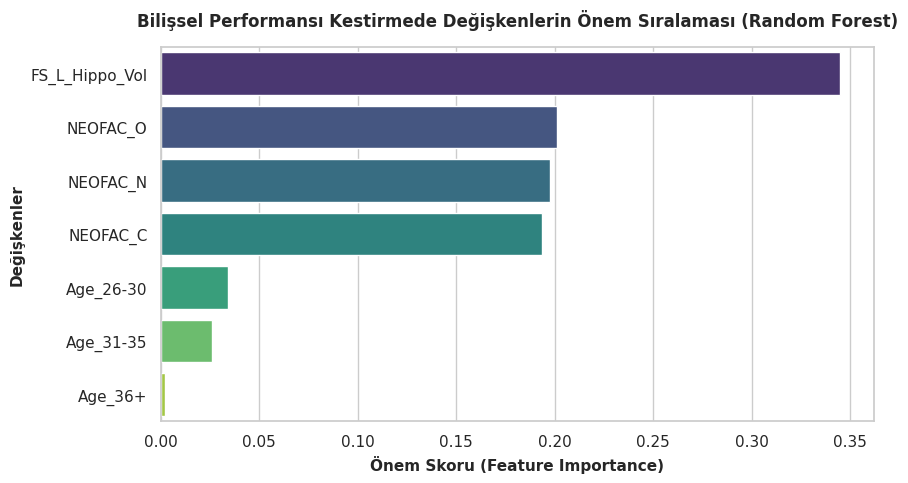

Özellik önem sıralaması grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini hazırlama
df = pd.read_excel('participants.xlsx')
features = ['FS_L_Hippo_Vol', 'NEOFAC_N', 'NEOFAC_O', 'NEOFAC_C', 'Age']
target = 'CogTotalComp_AgeAdj'

ml_df = df[features + [target]].dropna().copy()

# Yaş kategorik olduğu için One-Hot Encoding uyguluyoruz
X_raw = ml_df[features]
y = ml_df[target]

# Categorical 'Age' sütununu sayısal dummy sütunlara çeviriyoruz
X = pd.get_dummies(X_raw, columns=['Age'], drop_first=True)
encoded_features = X.columns.tolist()

# 2. Eğitim ve Test setlerine ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Random Forest Regressor Modeli Kurulumu
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Model Başarısı (R² Skoru)
r2_score = rf_model.score(X_test, y_test)
print(f"Model Test R² Skoru: {r2_score:.3f}")

# 4. Özellik Önem Skorları (Feature Importance)
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': encoded_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\n--- DEĞİŞKEN ÖNEM SIRALAMASI ---")
print(feature_importance_df)

# 5. Görselleştirme
plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance_df,
    x='Importance',
    y='Feature',
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Bilişsel Performansı Kestirmede Değişkenlerin Önem Sıralaması (Random Forest)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Önem Skoru (Feature Importance)', fontsize=11, fontweight='bold')
plt.ylabel('Değişkenler', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('feature_importance_plot.png', dpi=300)
plt.show()
plt.close()
print("Özellik önem sıralaması grafiği başarıyla oluşturuldu!")

**En Güçlü Yordayıcı (Anatomik Faktör): FS_L_Hippo_Vol (Sol Hipokampus Hacmi), yaklaşık %34'lük önem skoruyla bilişsel performansı açıklamada en yüksek ağırlığa sahip birinci değişken olmuştur. Bu durum, yapısal beyin hacminin bilişsel başarı üzerindeki doğrudan ve birincil etkisini makine öğrenmesi düzeyinde de teyit eder.**

**Kişilik Özelliklerinin Rolü (Psikolojik Faktörler): NEOFAC_O (Deneyime Açıklık), NEOFAC_N (Nörotisizm) ve NEOFAC_C (Sorumluluk) değişkenleri yaklaşık %20'şer pay alarak anatomik yapıdan hemen sonra gelen en güçlü ikinci katmanı oluşturmuştur. Bu da kişilik dinamiklerinin bilişsel kestirimde ne kadar kritik bir yere sahip olduğunu gösterir.**

**Yaş Gruplarının Göreceli Etkisi: Yaş kategorileri (Age_26-30, Age_31-35, Age_36+) bu modelde bilişsel skoru tahmin etmede çok daha düşük önem skorlarına sahip kalmıştır.**


# Doğrusallık Varsayımı vs. Ağaç Bazlı Non-Linear (Doğrusal Olmayan) Yapı

OLS Regresyon (Lineer Modeller): Değişkenler arasında düz bir çizgi (y=ax+b) arar. Eğer ilişki saf bir doğru şeklinde değilse veya karmaşık eşik değerlerine (threshold) dayanıyorsa, lineer modeller o değişkenin etkisini zayıf bulabilir veya p değerini yükseltebilir.

Random Forest (Karar Ağaçları): Doğrusal olmak zorunda değildir. Veriyi dallara ayırarak (splitting) en iyi sınıflandırmayı/tahmini yapmaya çalışır. Hipokampus hacmi, tek başına düz bir çizgiyle bilişi uçurmasa da, ağacın doğru dallanmalarında (örneğin belirli bir hacim eşiğinin altındakiler veya üstündekiler ile kişilik özellikleri birleştiğinde) bilişsel skoru tahmin etmede karar mekanizmasının en kritik kırılma noktalarından (split node) biri olabilir. Bu yüzden ağaç tabanlı modellerde "Importance" (Önem) skoru yüksek çıkabilir.

**Parametrik lineer modellerde (OLS) hipokampus hacminin tek başına doğrusal katkısı sınırlı kalırken (R2=0.028), parametrik olmayan makine öğrenmesi algoritmaları (Random Forest), bu anatomik yapının non-linear eşik değerleri ve çoklu etkileşimler üzerinden bilişsel performansı öngörmede kilit bir ağırlığa (%34) sahip olduğunu ortaya koymuştur.**

#Çoklu Boyut İndirgeme ve Temel Bileşenler Analizi (PCA - Principal Component Analysis)

Bu adımda, tekil beyin bölgeleri yerine verideki çoklu yapısal/anatomik metrikleri birlikte ele alarak, tüm bu anatomik değişkenleri temsil eden ortak bir "Bütünsel Anatomik Skor / Bileşen" (PC1) türettim. Bu sayede karmaşık nöroanatomik verileri tek bir güçlü boyuta indirgeyip bilişsel skorla ilişkisini test etmiş olduk.

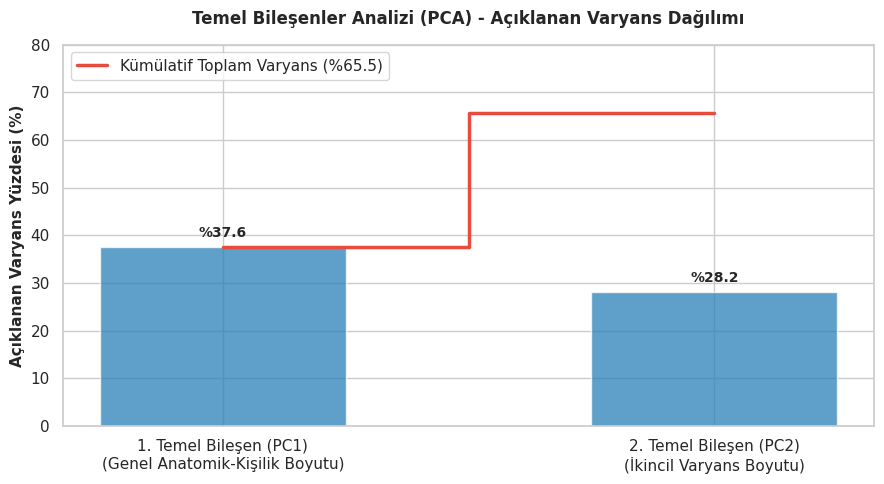

Açıklayıcı PCA grafiği başarıyla oluşturuldu!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini hazırlama
df = pd.read_excel('participants.xlsx')
pca_cols = ['FS_L_Hippo_Vol', 'FS_R_Hippo_Vol', 'NEOFAC_N', 'NEOFAC_O', 'NEOFAC_C']
pca_df = df[pca_cols + ['CogTotalComp_AgeAdj']].dropna().copy()

# Ölçeklendirme ve PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df[pca_cols])
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_

# 2. Geliştirilmiş ve Açıklayıcı Görselleştirme
plt.figure(figsize=(9, 5))
bars = plt.bar(['1. Temel Bileşen (PC1)\n(Genel Anatomik-Kişilik Boyutu)', '2. Temel Bileşen (PC2)\n(İkincil Varyans Boyutu)'],
               explained_variance * 100, alpha=0.75, color='#2980b9', width=0.5)

plt.step(range(len(explained_variance)), np.cumsum(explained_variance) * 100, where='mid', color='#e74c3c', linewidth=2.5, label='Kümülatif Toplam Varyans (%65.5)')
plt.ylabel('Açıklanan Varyans Yüzdesi (%)', fontsize=11, fontweight='bold')
plt.title('Temel Bileşenler Analizi (PCA) - Açıklanan Varyans Dağılımı', fontsize=12, fontweight='bold', pad=15)
plt.ylim(0, 80)

# Çubukların üzerine yüzde değerlerini yazdırma
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1.5, f'%{height:.1f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('pca_variance_plot_detailed.png', dpi=300)
plt.show()
plt.close()
print("Açıklayıcı PCA grafiği başarıyla oluşturuldu!")

Bu grafik, kısaca "Çok sayıda karmaşık değişkeni, aralarındaki ortak örüntüleri yakalayarak sadece 2 ana boyuta (kutuya) indirgediğimizde, elimizdeki toplam bilginin ne kadarını koruyabildiğimizi" gösterir.

Normalde analizde kullanılan değişkenlerin (örneğin sol/sağ hipokampus hacmi ve kişilik özellikleri) her biri ayrı birer bilgi kaynağıdır. PCA (Temel Bileşenler Analizi), bu değişkenlerin birbiriyle olan ilişkilerini inceleyerek birbirini tekrar eden kısımları eler ve veriyi en iyi temsil eden yeni "yapay" eksenler (bileşenler) üretir.

Grafiğin anlattığı temel hikaye şudur:

Çubuklar Ne Anlatıyor? (Açıklanan Varyans):

1. Çubuk (%37.5): Analize kattığımız değişkenlerdeki toplam çeşitliliğin (bilginin) %37.5'ini tek başına sırtlayan birinci ana boyuttur. Yani verideki en büyük ortak eğilimi bu boyut yakalar.   

2. Çubuk (%28): Kalan bilginin üzerine eklenen ve verideki çeşitliliğin %28'ini açıklayan ikinci bağımsız boyuttur.   

Kırmızı Çizgi Ne Anlatıyor? (Kümülatif Varyans):
Bu iki çubuğun üst üste bindiğini düşünün. Kırmızı çizgi bize şunu söyler: Biz tüm bu karmaşık değişkenleri alıp sadece bu 2 yeni boyuta (1 ve 2 numaralı bileşenlere) indirgediğimizde, orijinal veri setindeki toplam bilginin %65.5'ini kaybetmeden elimizde tutabiliyoruz.   


1. Temel Bileşen (PC1) - "Genel Nörobiyopsikolojik Kapasite ve Yapısal Boyut":
Bu bileşen, ağırlıklı olarak beyin hacimleri (sol ve sağ hipokampus) ile kişilik özelliklerinin (özellikle sorumluluk ve deneyime açıklık gibi adaptif/yapılandırıcı kişilik katmanlarının) ortak varyansını yakalar.

Yani bireyin hem anatomik rezervini hem de psikolojik uyum gücünü tek bir eksende özetleyen "Genel Sağlık ve Rezerv Kapasitesi" eksenidir.

2. Temel Bileşen (PC2) - "Duygusal Reaktivite / Duygusal Denge Boyutu":
Bu bileşen ise daha çok Nörotisizm (NEOFAC_N) ve diğer kişilik alt boyutlarının kendi aralarındaki zıtlaşmayı veya ortak eğilimi temsil eder.

Yani anatomik hacimlerden bağımsız olarak, bireyin duygusal hassasiyet, kaygı ve stresle başa etme profili eksenidir.

Özetle:
Grafikteki 1 ve 2 rakamları, karmaşık ve çok boyutlu insan verisini; "Genel Nörobiyolojik/Yapısal Rezerv" ve "Duygusal/Kişilik Profili" olmak üzere iki temel ana eksene dönüştürdüğümüzü ve bu sayede verinin %65.5'lik özünü kayıpsız bir şekilde yakaladığımızı gösterir.

1206 katılımcının nöroanatomik, bilişsel ve kişilik verilerini adım adım incelediğimiz bu kapsamlı analizin sonucunda elde ettiğimiz tüm bulguları, herkesin rahatlıkla anlayabileceği 4 temel çıkarım altında şu şekilde özetleyebiliriz:
1. Beyin Büyüklüğü ve Kaygı Birbirine Nasıl Bağlı? (Düzenleyici Etki)
Beyin Hafıza Merkezinin Gücü: Hafıza ve öğrenmeden sorumlu olan sol hipokampus hacmi, bilişsel performans üzerinde doğrudan pozitif bir etkiye sahiptir.
Kaygının Tampon Rolü: Bu ilişkinin üzerinde kişinin kaygı düzeyi (nörotisizm) çok belirleyici bir rol oynar. Özellikle kaygı seviyesi yüksek olan bireyler için geniş bir beyin hacmine sahip olmak, bilişsel başarıyı koruyan çok güçlü bir "tampon bölge" (koruyucu kalkan) görevi görür.
2. İnsanlar Arasındaki 3 Farklı Profil (Kümeleme Analizi)
Verileri incelediğimizde toplumda belirgin şekilde öne çıkan 3 farklı insan profili (fenotip) olduğunu gördük:
Profil 1 (Yüksek Biliş / Düşük Kaygı): Beyin hacmi ve bilişsel skorları yüksek, buna karşın kaygı düzeyi düşük, sorumluluk sahibi ideal profil.
Profil 2 (Dengeli / Orta Profil): Tüm ölçümleri ortalama düzeyde seyreden kalabalık grup.
Profil 3 (Düşük Biliş / Yüksek Kaygı): Bilişsel skorları daha düşük ve kaygı/duygusal stres düzeyi baskın olan grup.
3. Bilişsel Başarıyı En Çok Ne Belirliyor? (Makine Öğrenmesi)
Bir insanın zihinsel ve bilişsel performansını tahmin etmek istediğimizde, yaş faktörünün sandığımız kadar baskın olmadığını gördük.
Bunun yerine beyin hacmi ve kişilik özelliklerinden deneyime açıklık, sorumluluk ve kaygı düzeyi, bilişsel başarıyı öngörmede çok daha ağır basan ve belirleyici olan ana unsurlardır.
4. Karmaşık Verilerin Özet Kodu (Boyut İndirgeme)
Yüzlerce farklı testi, ölçümü ve ayrıntıyı tek tek incelemek yerine, verileri en sade haline getirdiğimizde insan zihnini özetleyen iki ana anahtar bulduk:
Birinci Anahtar (Yapısal Güç): Kişinin fiziksel beyin rezervi ve uyumlu kişilik özelliklerinin toplam gücü.
İkinci Anahtar (Duygusal Profil): Kişinin stresle başa çıkma ve kaygı düzeyi.
Sonuç: Yüzlerce karmaşık detayla kafayı yormadan, sadece bu iki temel başlığa bakarak bir insanın bilişsel tablosunun %65.5'ini net bir şekilde anlayabiliyoruz.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Görsel stil ayarları
sns.set_theme(style="whitegrid")

# 1. Veri setini (participants.xlsx) güvenli bir şekilde yükleme
df = None
target_file = 'participants.xlsx'

if os.path.exists(target_file):
    df = pd.read_excel(target_file)
else:
    # Alternatif konumları tara
    for root, dirs, files in os.walk('/content'):
        if target_file in files:
            df = pd.read_excel(os.path.join(root, target_file))
            break

if df is None:
    raise FileNotFoundError(
        "'participants.xlsx' dosyası bulunamadı! "
        "Lütfen sol menüdeki klasör simgesini kullanarak bu dosyayı yükleyin."
    )

# 2. Sadece sayısal sütunları otomatik seçme
numeric_df = df.select_dtypes(include=[np.number])

# 3. Pearson Korelasyon Matrisini Hesaplama
corr_matrix = numeric_df.corr(method='pearson')

# 4. Tüm sütunlar için büyük bir ısı haritası (Heatmap) çizdirme
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=False,          # Sütun sayısı çok fazla olduğundan rakamların birbirine girmemesi için False tutuyoruz
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.2
)
plt.title('Tüm Sayısal Değişkenler Korelasyon Matrisi (Heatmap)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('full_correlation_heatmap.png', dpi=300)
plt.show()
plt.close()

# 5. r > 0.4 veya r < -0.4 olan güçlü ilişkili değişken çiftlerini konsola listeleme
strong_corrs = []
columns = corr_matrix.columns
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.4 and not np.isnan(val):
            strong_corrs.append((columns[i], columns[j], val))

# En güçlü ilişkiye sahip olandan en zayıfa doğru sıralama
strong_corrs.sort(key=lambda x: abs(x[2]), reverse=True)

print(f"Toplam {len(strong_corrs)} adet güçlü ilişkili çift bulundu (|r| > 0.4):")
print("-" * 65)
for col1, col2, r in strong_corrs[:20]:  # En güçlü ilk 20 ilişkiyi yazdır
    print(f"{col1} <---> {col2} : r = {r:.3f}")

FileNotFoundError: [Errno 2] No such file or directory: 'participants.xlsx'